# 03 — Forecasting & Scenario Analysis
Reproduces and visualizes what `src/forecasting.py` computes, matching
**Module 4: Forecasting & Scenario Analysis**.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED_DIR = os.path.join("..", "data", "processed")

forecast = pd.read_csv(os.path.join(PROCESSED_DIR, "sales_forecast.csv"), parse_dates=["month"])
forecast.head()

,product_id,brand_name,month,actual_net_sales,forecast_net_sales,scenario,is_forecast
0,P001,ONCO-A1,2022-01-01,844765.39,NaN,Actual,False
1,P001,ONCO-A1,2022-02-01,779383.77,NaN,Actual,False
2,P001,ONCO-A1,2022-03-01,845860.78,NaN,Actual,False
3,P001,ONCO-A1,2022-04-01,789269.39,NaN,Actual,False
4,P001,ONCO-A1,2022-05-01,815832.84,NaN,Actual,False


## Company-wide actual vs Base Case forecast

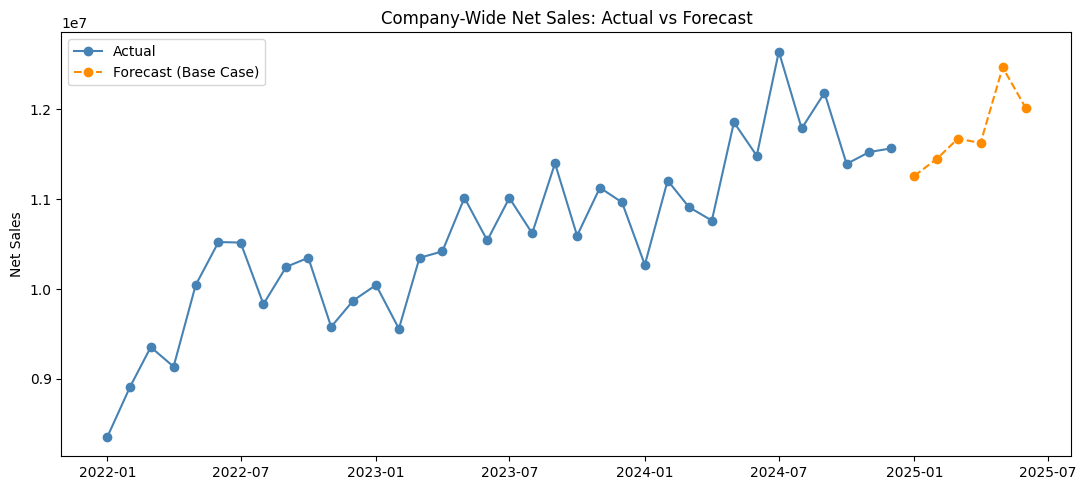

In [2]:
actual = forecast[forecast["scenario"] == "Actual"].groupby("month")["actual_net_sales"].sum()
base_case = forecast[forecast["scenario"] == "Base Case"].groupby("month")["forecast_net_sales"].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(actual.index, actual.values, label="Actual", color="steelblue", marker="o")
ax.plot(base_case.index, base_case.values, label="Forecast (Base Case)", color="darkorange", marker="o", linestyle="--")
ax.set_title("Company-Wide Net Sales: Actual vs Forecast")
ax.set_ylabel("Net Sales")
ax.legend()
plt.tight_layout()
plt.show()

## Scenario comparison (next N months, company-wide)

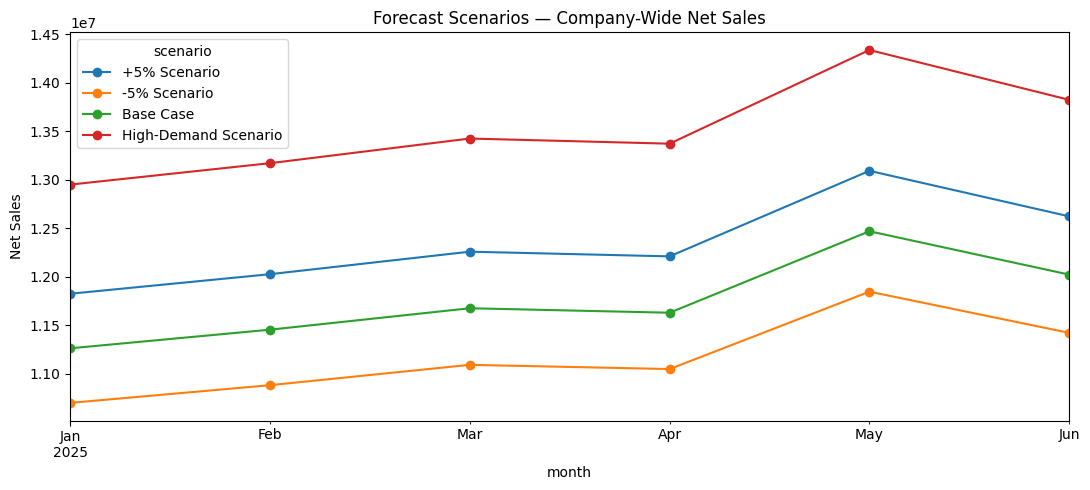

scenario,+5% Scenario,-5% Scenario,Base Case,High-Demand Scenario
month,,,,
2025-01-01,11823286.67,10697259.37,11260273.01,12949313.97
2025-02-01,12024980.69,10879744.43,11452362.57,13170216.95
2025-03-01,12257191.45,11089839.91,11673515.68,13424543.03
2025-04-01,12208856.26,11046108.05,11627482.15,13371604.49
2025-05-01,13091471.90,11844665.06,12468068.46,14338278.76
2025-06-01,12621619.38,11419560.39,12020589.90,13823678.40


In [3]:
scenarios = forecast[forecast["is_forecast"] == True]
scenario_totals = scenarios.groupby(["month", "scenario"])["forecast_net_sales"].sum().unstack("scenario")

scenario_totals.plot(marker="o", figsize=(11, 5), title="Forecast Scenarios — Company-Wide Net Sales")
plt.ylabel("Net Sales")
plt.tight_layout()
plt.show()
scenario_totals

## Product-level forecast (top 5 products by historical sales)

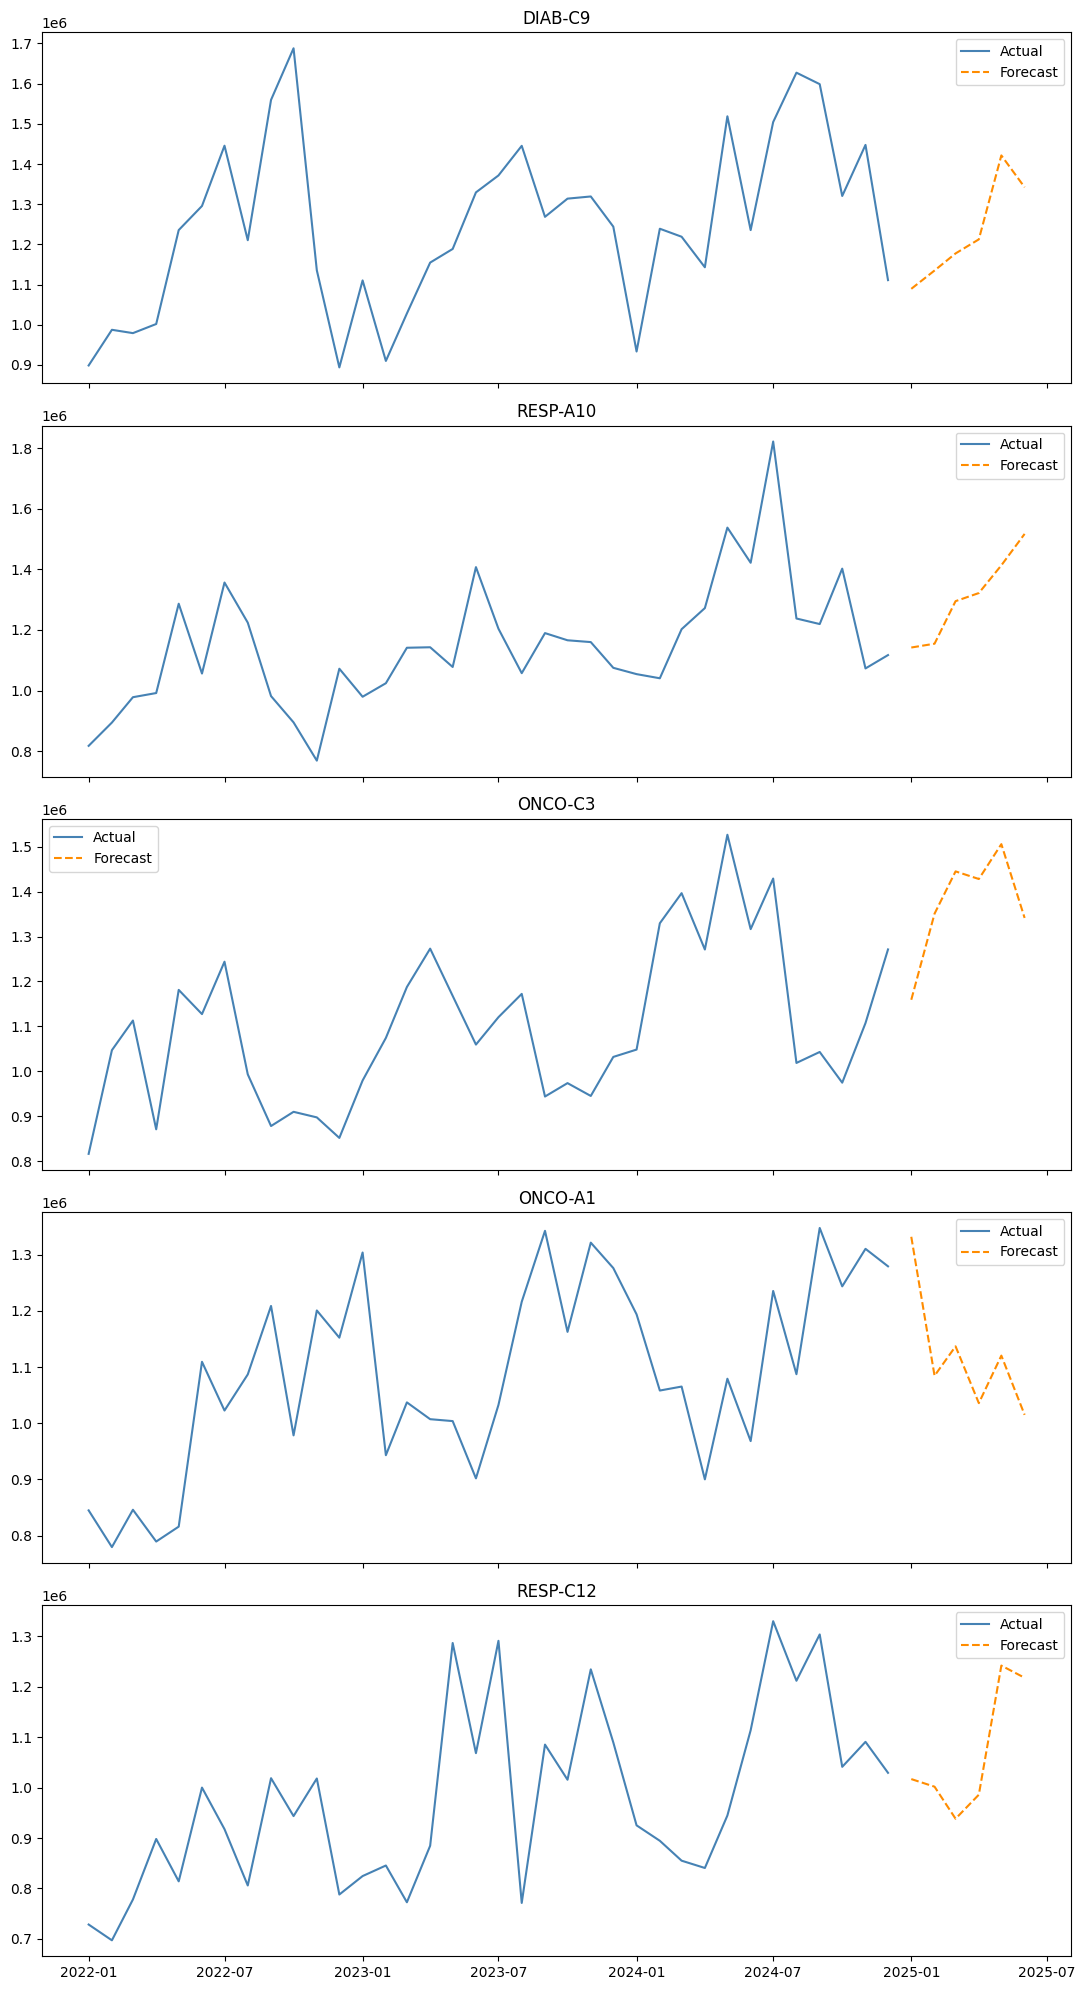

In [4]:
top_products = (
    forecast[forecast["scenario"] == "Actual"]
    .groupby("brand_name")["actual_net_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

fig, axes = plt.subplots(len(top_products), 1, figsize=(11, 4 * len(top_products)), sharex=True)
for ax, brand in zip(axes, top_products):
    prod_data = forecast[forecast["brand_name"] == brand]
    actual_p = prod_data[prod_data["scenario"] == "Actual"].set_index("month")["actual_net_sales"]
    base_p = prod_data[prod_data["scenario"] == "Base Case"].set_index("month")["forecast_net_sales"]
    ax.plot(actual_p.index, actual_p.values, label="Actual", color="steelblue")
    ax.plot(base_p.index, base_p.values, label="Forecast", color="darkorange", linestyle="--")
    ax.set_title(brand)
    ax.legend()
plt.tight_layout()
plt.show()

## Summary
- The Base Case forecast extrapolates recent trend + seasonality per
  product using Holt-Winters exponential smoothing (falling back to a
  simple linear trend for short histories).
- `+5%` / `-5%` / `High-Demand` scenarios apply flat multipliers to the
  Base Case to give planning teams a quick sensitivity range without
  re-running the model.